<a href="https://colab.research.google.com/github/LeylahfrA01178568/2039_data_visualization/blob/main/regression_Class_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn import linear_model

In [ ]:
path = 'https://raw.githubusercontent.com/tec03/Datasets/refs/heads/main/datasets/reg_data.csv'

In [ ]:
df =pd.read_csv(path)
df.head()

,Gender,Age,Place,Weight,Company,Education,JoinYear,Salary
0,Male,58.0,NaN,70.7,GM,Master,2006.0,74862.0
1,Female,56.0,1.0,65.9,BMW,Master,2021.0,60652.0
2,Male,54.0,2.0,88.9,BMW,PhD,2011.0,65058.0
3,Male,26.0,3.0,63.2,Tesla,PhD,2016.0,46284.0
4,Male,49.0,4.0,60.9,GM,Master,2012.0,60945.0


## What is the Salary of Female person with age 56, from Place 1, with weight 65.9, working BMW, with Masters education, joined 2001?

In [ ]:
df.Place.unique()

array([nan,  1.,  2.,  3.,  4.])

In [ ]:
df.isnull().any()

,0
Gender,True
Age,True
Place,True
Weight,True
Company,True
Education,True
JoinYear,True
Salary,True


In [ ]:
df.isnull().any()

,0
Gender,True
Age,True
Place,True
Weight,True
Company,True
Education,True
JoinYear,True
Salary,True


## 1. What is the Salary of a person with age 56?

`Salary = b0 + b1*Age`

In [ ]:
favs = ['Salary', 'Age', 'Gender']
ndf = df[favs].dropna()
ndf.isnull().any()

,0
Salary,False
Age,False
Gender,False


In [ ]:
df = df.dropna()

### Option 1: Manchine Learning way

In [ ]:
X = pd.DataFrame(ndf['Age'])
y = pd.DataFrame(ndf['Salary'])



lm = linear_model.LinearRegression()
model_lm = lm.fit(X,y)

In [ ]:
type (X)
type(y)

pandas.core.frame.DataFrame

In [ ]:
age_coef = model_lm.coef_[0]
age_coef

array([474.88311354])

In [ ]:
b0 = model_lm.intercept_
b0

array([41324.8501759])

In [ ]:
model_lm.score(X,y) # r^2 how much variance it explains

0.6364727494094164

In [ ]:
age= int(input('Enter age to find salary'))

Enter age to find salary56


In [ ]:
print('The salary of a person with Age {age} i\s t', float(b0+age_coef*age))

The salary of a person with Age {age} i\s t 67918.3045342143


<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_3075/2640922761.py:1: SyntaxWarning: invalid escape sequence '\s'
  print('The salary of a person with Age {age} i\s t', float(b0+age_coef*age))
/tmp/ipykernel_3075/2640922761.py:1: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print('The salary of a person with Age {age} i\s t', float(b0+age_coef*age))


### Option 2:

In [ ]:
reg_eqn = 'Salary ~ Age'
modelA = sm.OLS.from_formula(reg_eqn, data = ndf).fit()
modelA.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.636
Model:                            OLS   Adj. R-squared:                  0.634
Method:                 Least Squares   F-statistic:                     220.6
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           1.82e-29
Time:                        00:26:21   Log-Likelihood:                -1250.0
No. Observations:                 128   AIC:                             2504.
Df Residuals:                     126   BIC:                             2510.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   4.132e+04   1348.047     30.655      0.000    3.87e+04     4.4e+04
Age          474.8831     31.973     14.853      0.000     411.610     538.156
==============================================================================
Omnibus:                       10.694   Durbin-Watson:                   1.811
Prob(Omnibus):                  0.005   Jarque-Bera (JB):               11.906
Skew:                           0.559   Prob(JB):                      0.00260
Kurtosis:                       3.992   Cond. No.                         151.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
modelA.params

,0
Intercept,41324.850176
Age,474.883114


In [ ]:
modelA.resid


,0
0,5993.929239
1,-7266.304534
2,-1910.538307
3,-7387.811128
4,-3649.122739
...,...
144,-1506.590285
145,-394.109809
146,-3907.460469
148,-3742.953875


In [ ]:
modelA.fittedvalues

,0
0,68868.070761
1,67918.304534
2,66968.538307
3,53671.811128
4,64594.122739
...,...
144,62694.590285
145,56521.109809
146,55096.460469
148,69342.953875


In [ ]:
study = [df['Age'],df['Salary'], modelA.fittedvalues, modelA.resid]
pd.concat(study, axis=1)

,Age,Salary,0,1
1,56.0,60652.0,67918.304534,-7266.304534
2,54.0,65058.0,66968.538307,-1910.538307
3,26.0,46284.0,53671.811128,-7387.811128
4,49.0,60945.0,64594.122739,-3649.122739
8,33.0,50506.0,56995.992923,-6489.992923
...,...,...,...,...
139,NaN,NaN,58895.525377,3606.474623
141,NaN,NaN,60795.057831,-572.057831
145,NaN,NaN,56521.109809,-394.109809
146,NaN,NaN,55096.460469,-3907.460469


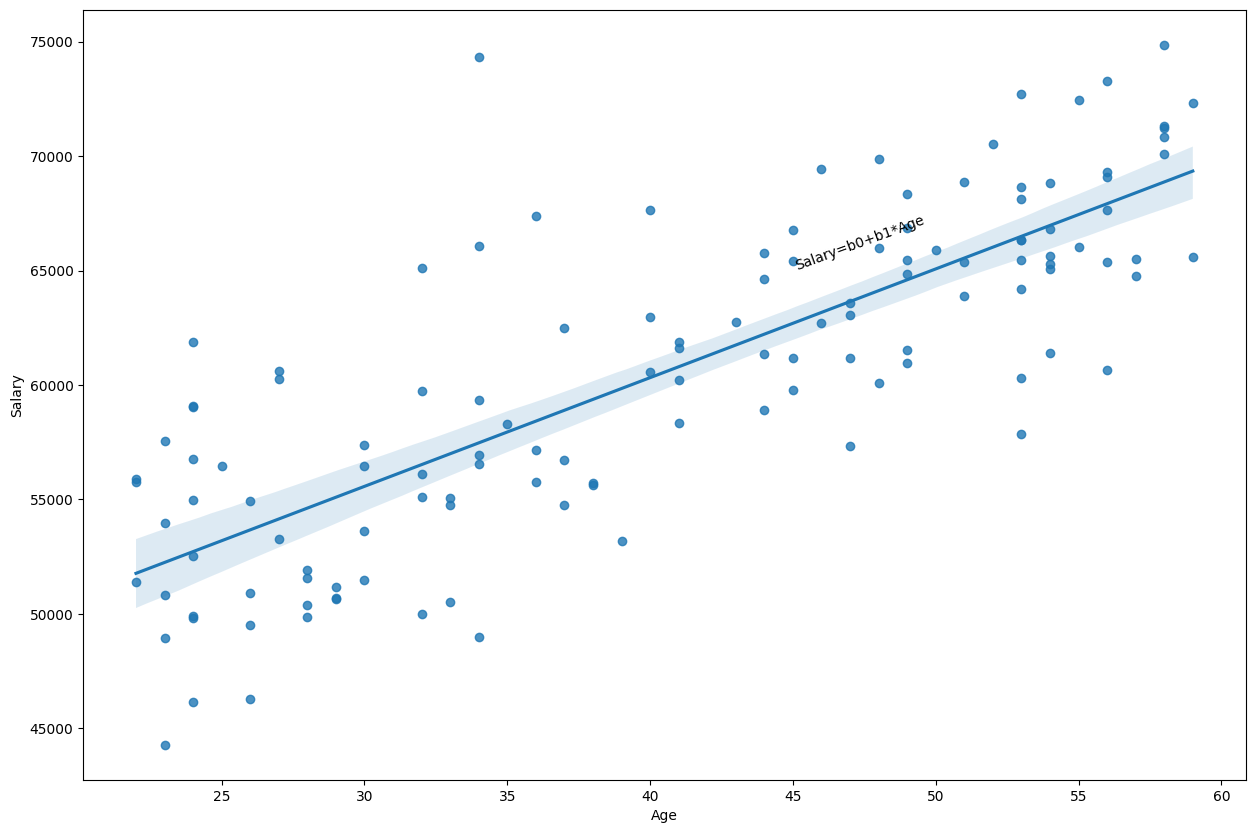

In [ ]:
plt.figure(figsize=(15,10))
ax =sns.regplot(x='Age',y='Salary',data=ndf)
ax.set(xlabel='Age',ylabel='Salary')
ax.text(45,65050,'Salary=b0+b1*Age', rotation=20, size='medium')
plt.show()

## 2.1 What is the `Salary`of a Female with Age 56?